In [2]:
import numpy as np
import h5py
import matplotlib.pyplot as plt

with h5py.File('half_filling_data_20260704_112620.h5', 'r') as f:
    print(f.keys())
    # print(f['mz_array'][:])
    eigvals = f['eigvals'][:]
    data = f['data'][:]
    w_array = f['w_array'][:]
    mz_array = f['mz_array'][:]

print(data.shape)

print(eigvals.shape)
print(w_array)
print(mz_array)

<KeysViewHDF5 ['data', 'eigvals', 'mz_array', 'w_array']>


(10000, 41)
(10000, 41, 1000)
[0.  0.2 0.4 0.6 0.8 1.  1.2 1.4 1.6 1.8 2.  2.2 2.4 2.6 2.8 3.  3.2 3.4
 3.6 3.8 4.  4.2 4.4 4.6 4.8 5.  5.2 5.4 5.6 5.8 6.  6.2 6.4 6.6 6.8 7.
 7.2 7.4 7.6 7.8 8. ]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


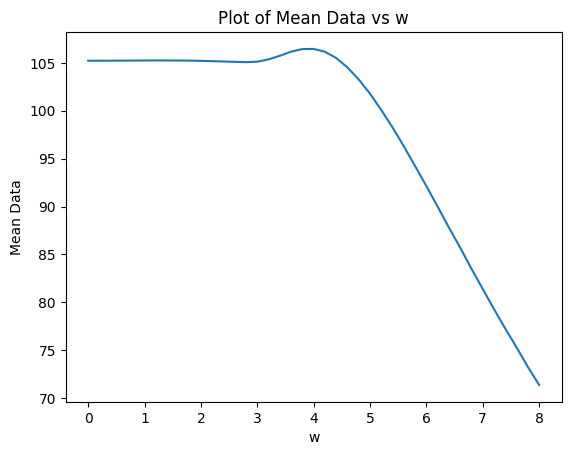

/tmp/ipykernel_3892586/2702000815.py:7: RuntimeWarning: divide by zero encountered in log
  plt.plot(w_array, np.gradient(np.mean(data, axis=0) - np.mean(data, axis=0)[0], np.log(w_array)))


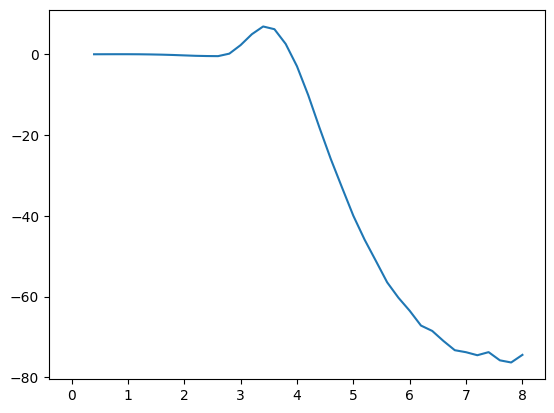

In [ ]:
# Tell andras about new dataset
import matplotlib.pyplot as plt
plt.plot(w_array, np.mean(data, axis=0))
plt.xlabel('w')
plt.ylabel('Mean Data')
plt.title('Plot of Mean Data vs w')
plt.show()
plt.plot(w_array, np.gradient(np.mean(data, axis=0) - np.mean(data, axis=0)[0], np.log(w_array)))

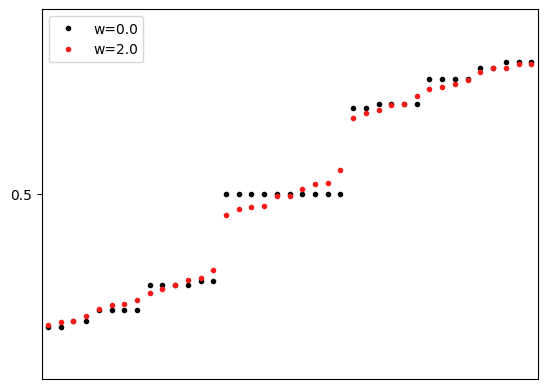

(2, 1000)


In [27]:
import matplotlib.pyplot as plt
special1 = eigvals[0, 0]
special2 = eigvals[0, 10]
color1 = '#000000'
color2 = '#FB1A18'
plt.plot(special1, '.', color=color1, label=r'w=0.0')
plt.plot(special2, '.', color=color2, label=r'w=2.0')
plt.xlim(480.5, 519.5)
plt.yticks([0.5])
plt.xticks([])
plt.legend(loc='upper left')
plt.savefig('entanglement_spectrum_1c.pdf', bbox_inches='tight')
plt.show()
print(np.concatenate([special1[None, :], special2[None, :]], axis=0).shape)
with h5py.File('entanglement_spectrum_1c.h5', 'w') as f:
    f.create_dataset('eigvals', data=np.concatenate([special1[None, :], special2[None, :]], axis=0))
    f.create_dataset('w_array', data=np.array([0.0, 2.0]))

In [2]:
def compute_renyi_entropy(data, alpha):
    data_filtered = np.clip(data, 1e-10, 1 - 1e-10)  # Avoid log(0)
    if alpha == 1:
        # Shannon entropy
        return -np.mean(data_filtered * np.log(data_filtered) + (1-data_filtered) * np.log(1-data_filtered), axis=0)
    elif alpha == np.inf:
        return -np.mean(np.log(np.maximum(data_filtered, 1-data_filtered)), axis=0)
    else:
        # Renyi entropy
        return (1 / (1 - alpha)) * np.mean(np.log(data_filtered ** alpha + (1-data_filtered) ** alpha), axis=0)

In [3]:
def compute_moments(data, order=5):
    all_moments = []
    for i in range(order):
        moment = np.mean(data ** (i + 1), axis=0)
        # print(f"Moment {i + 1}: {moment}")
        all_moments.append(moment)

    return all_moments


Computing moments: 100%|██████████| 21/21 [00:00<00:00, 39.39it/s]


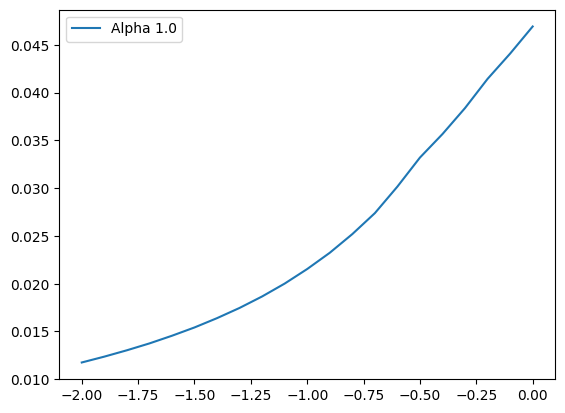

Computing moments: 100%|██████████| 21/21 [00:00<00:00, 59.60it/s]


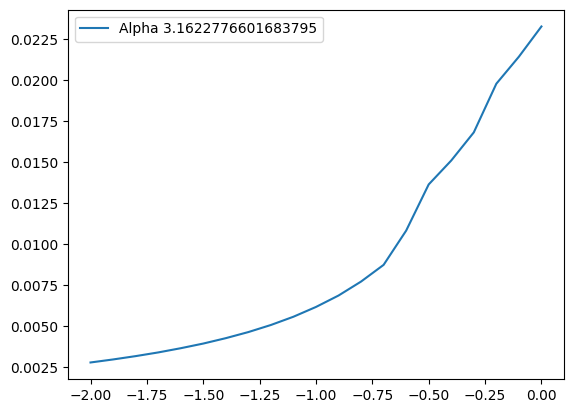

Computing moments: 100%|██████████| 21/21 [00:00<00:00, 63.68it/s]


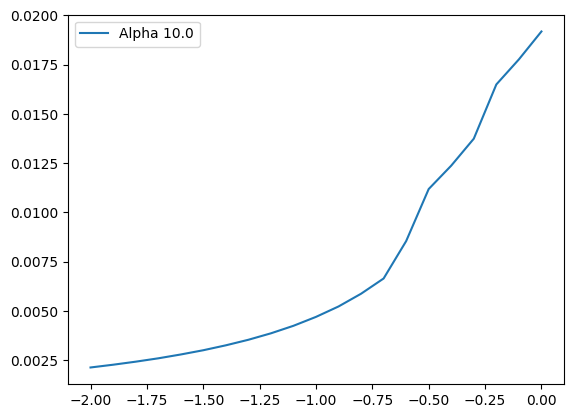

Computing moments: 100%|██████████| 21/21 [00:00<00:00, 44.77it/s]


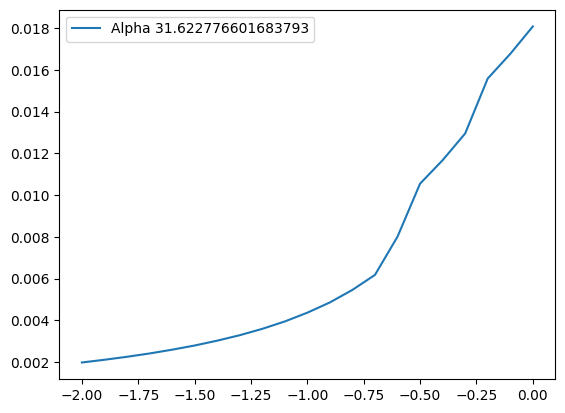

Computing moments: 100%|██████████| 21/21 [00:00<00:00, 26.59it/s]


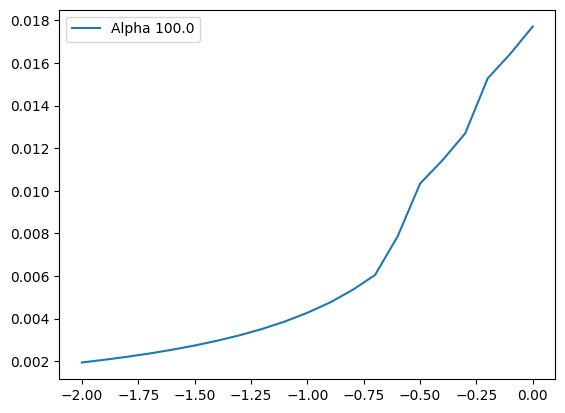

Computing moments: 100%|██████████| 21/21 [00:00<00:00, 25.29it/s]


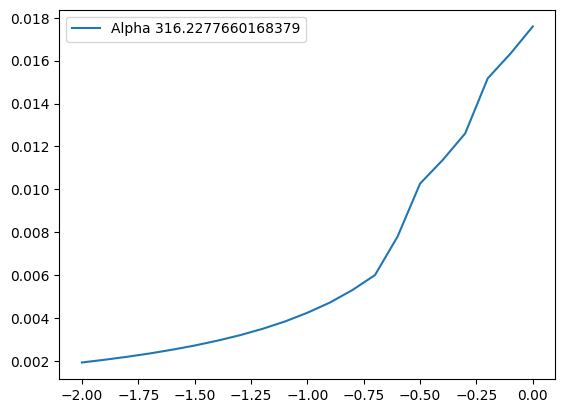

Computing moments: 100%|██████████| 21/21 [00:00<00:00, 28.13it/s]


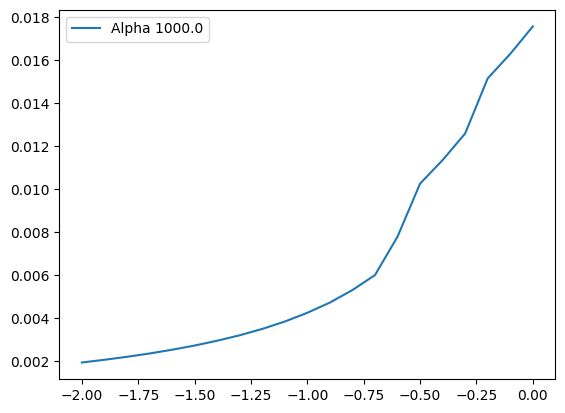

In [4]:
import matplotlib.pyplot as plt
from tqdm import tqdm
alpha_array = np.arange(1, 6)
alpha_array = np.logspace(0, 3, num=7)
all_entropies = np.zeros((len(alpha_array), len(w_array)))
for i, alpha in enumerate(alpha_array):
    for j, w in tqdm(enumerate(w_array), total=len(w_array), desc="Computing moments"):
        all_entropies[i, j] = compute_renyi_entropy(eigvals[:, j, :].flatten(), alpha=alpha)
    plt.plot(w_array, all_entropies[i], label=f'Alpha {alpha}')
    plt.legend()
    plt.show()



-2.3220487


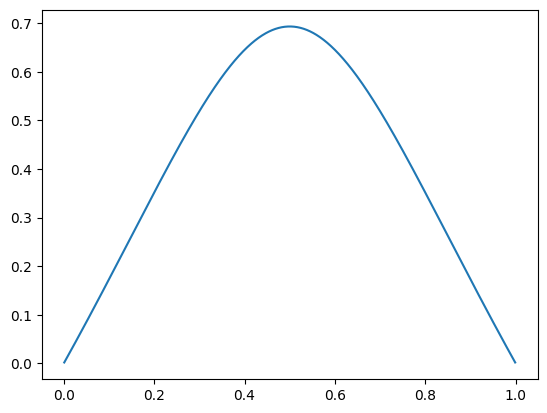

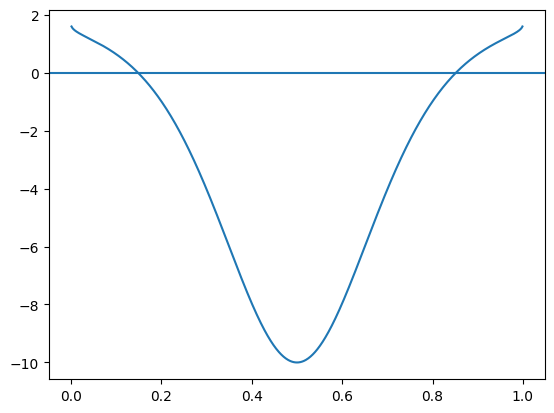

In [15]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""  # Use the first GPU
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

alpha = 2.5

g = lambda x: 1/(1-alpha)*jnp.log(x**alpha + (1-x)**alpha)

# Compose grad twice
d1 = jax.grad(g)
d2 = jax.grad(d1)

# Evaluate at a point
x = 0.25  # must be a float, not int
print(d2(x))  # scalar output

x = jnp.linspace(0.001, 0.999, 999)
d0_vectorized = jax.vmap(g)
d1_vectorized = jax.vmap(d1)
d2_vectorized = jax.vmap(d2)
y0 = d0_vectorized(x)
y1 = d1_vectorized(x)
y2 = d2_vectorized(x)

plt.plot(x, y0)
plt.show()

plt.plot(x, y2)
plt.axhline(0)
plt.show()

  message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.00014569456388788824
        x: [ 4.544e+01]
      nit: 14
      jac: [-6.558e-06]
     nfev: 30
     njev: 15
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>


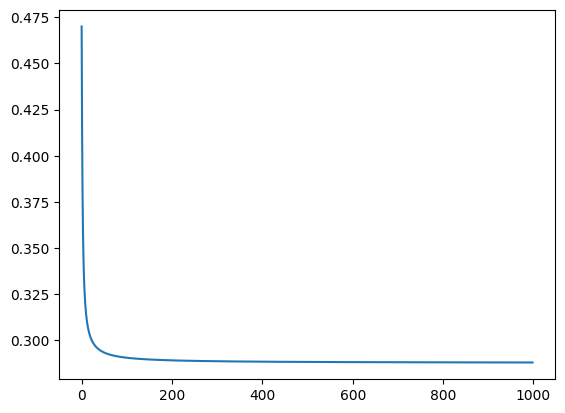

In [ ]:
# Find critical alpha:
import scipy
def f(alpha):
    x = 0.25
    return -1/(1-alpha)**2 * (np.log(x**alpha + (1-x)**alpha) + (1-alpha)*(x**alpha * np.log(x) + (1-x)**alpha * np.log(1-x)) / (x**alpha + (1-x)**alpha))

result = scipy.optimize.minimize(f, x0=2.0, bounds=[(1.01, 100)])

print(result)


g = lambda alpha: 1/(1-alpha)*np.log(0.25**alpha + (1-0.25)**alpha)
plt.plot([g(alpha) for alpha in np.linspace(2, 1000, 999)], label='g(alpha)')

/tmp/ipykernel_285002/1829960854.py:1: RuntimeWarning: invalid value encountered in divide
  plt.plot(w_array, ((all_entropies - all_entropies[:, 0][:, None])/(all_entropies[0, :][None, :] - all_entropies[0, 0])).T)


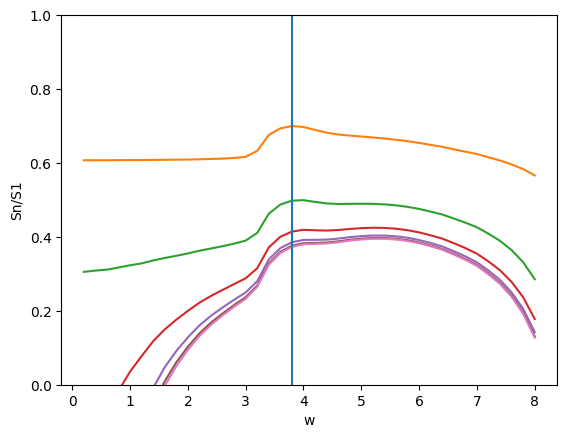

In [63]:
plt.plot(w_array, ((all_entropies - all_entropies[:, 0][:, None])/(all_entropies[0, :][None, :] - all_entropies[0, 0])).T)
plt.axvline(x=3.8)
plt.ylim(0, 1)
plt.xlabel('w')
plt.ylabel('Sn/S1')
plt.show()

/tmp/ipykernel_285002/2334647574.py:1: RuntimeWarning: divide by zero encountered in log
  plt.plot(np.log(w_array), np.gradient(np.log(all_entropies-all_entropies[:, 0][:, None]).T, np.log(w_array), axis=0))
/tmp/ipykernel_285002/2334647574.py:1: RuntimeWarning: invalid value encountered in log
  plt.plot(np.log(w_array), np.gradient(np.log(all_entropies-all_entropies[:, 0][:, None]).T, np.log(w_array), axis=0))
/scratch/vimohr/master_project/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:1291: RuntimeWarning: invalid value encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/scratch/vimohr/master_project/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:1292: RuntimeWarning: invalid value encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))
/scratch/vimohr/master_project/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:1298: RuntimeWarning: invalid value encountered in multiply
  out[tuple(slice1)] = a * f[tuple(slice2)] + 

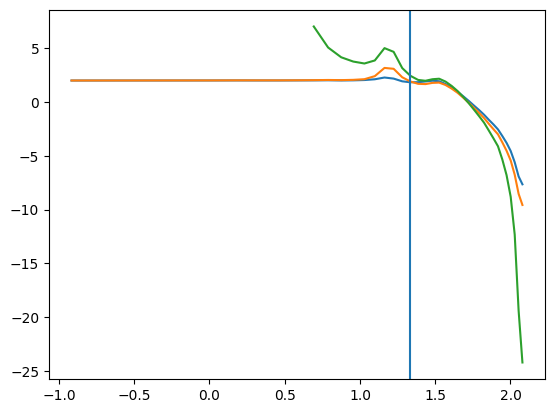

/tmp/ipykernel_285002/2334647574.py:5: RuntimeWarning: divide by zero encountered in log
  plt.plot(np.log(w_array), np.log(all_entropies-all_entropies[:, 0][:, None]).T)
/tmp/ipykernel_285002/2334647574.py:5: RuntimeWarning: invalid value encountered in log
  plt.plot(np.log(w_array), np.log(all_entropies-all_entropies[:, 0][:, None]).T)


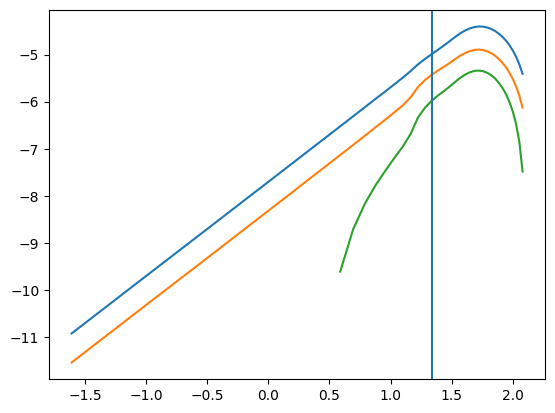

In [41]:
plt.plot(np.log(w_array), np.gradient(np.log(all_entropies-all_entropies[:, 0][:, None]).T, np.log(w_array), axis=0))
plt.axvline(x=np.log(3.8))
plt.show()

plt.plot(np.log(w_array), np.log(all_entropies-all_entropies[:, 0][:, None]).T)
plt.axvline(x=np.log(3.8))
plt.show()

/tmp/ipykernel_285002/2448881548.py:4: RuntimeWarning: divide by zero encountered in log
  plt.plot(x_array, np.log(np.sort(special_eigvals.flatten())))
/tmp/ipykernel_285002/2448881548.py:4: RuntimeWarning: invalid value encountered in log
  plt.plot(x_array, np.log(np.sort(special_eigvals.flatten())))


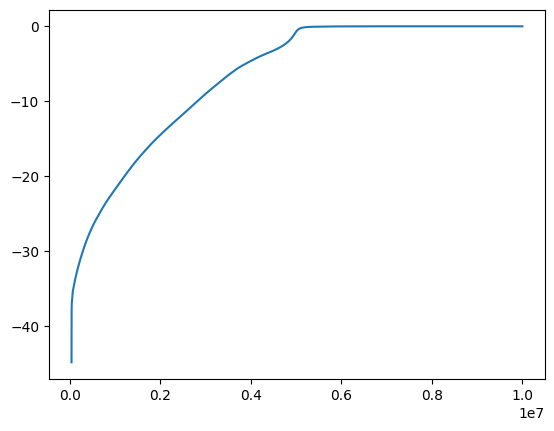

In [16]:
import matplotlib.pyplot as plt
special_eigvals = eigvals[:, 40, :]
x_array = np.arange(special_eigvals.flatten().shape[0])
plt.plot(x_array, np.log(np.sort(special_eigvals.flatten())))
plt.show()